# Q2 · Notebook 1 — Dataset loading and the two preprocessing pipelines

**Task.** 5-class star-rating prediction on the Amazon Reviews (English) dataset
(`SetFit/amazon_reviews_multi_en`: 200,000 train / 5,000 validation / 5,000 test).

This notebook

1. loads the dataset and builds one input text per review: **title + ". " + body**;
2. runs the **classic pipeline** for the BiGRU baseline: HTML/URL cleaning → lowercasing →
   spaCy tokenization → vocabulary (min. frequency 3) → integer ids, max 200 tokens →
   pre-trained **fastText** vectors loaded into an embedding matrix;
3. runs the **RoBERTa pipeline**: `RobertaTokenizerFast` byte-level BPE with `<s> … </s>`,
   truncation to 256 tokens, attention masks, and **dynamic padding** with a data collator.

Everything is cached under `data/`, so the training notebooks start immediately.

In [1]:
# --- Setup: work from the project root (the folder that contains src/) ---------------
# Colab: upload q2_rating_prediction.zip, then run
#   !unzip -q q2_rating_prediction.zip -d /content && %cd /content/q2_rating_prediction
# (or keep it on Google Drive so outputs survive a disconnect - see README).
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("project root:", ROOT)

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, Markdown, display
pd.set_option("display.max_colwidth", 160)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

project root: /content/q2_rating_prediction


torch 2.11.0+cu130 | GPU: Tesla T4


## 1. Load the dataset and merge title + body

The SetFit copy of the corpus only keeps the review **body** in its `text` column. The
assignment asks for title + body, so `load_reviews()` recovers each review's title from
the MTEB copy of the same corpus (which stores `title\nbody`) by matching the body text,
then concatenates them. `merge_stats` reports how many titles were recovered — **quote
this coverage in the report**. If the title source cannot be downloaded, the code falls back
to the body only and says so.

In [2]:
from src.data import load_reviews, merge_title_body
ds, merge_stats = load_reviews("data")
print(ds)
{k: v for k, v in merge_stats.items() if "coverage" in k or "size" in k or k == "title_source"}

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'body', 'text', 'label'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'title', 'body', 'text', 'label'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'title', 'body', 'text', 'label'],
        num_rows: 5000
    })
})


{'title_source': 'mteb/AmazonReviewsClassification/en',
 'train_size': 200000,
 'train_title_coverage': 0.995855,
 'validation_size': 5000,
 'validation_title_coverage': 0.9966,
 'test_size': 5000,
 'test_title_coverage': 0.9972}

In [3]:
sample = ds["train"].select(range(6)).to_pandas()
sample.assign(stars=sample.label + 1)[["id", "title", "body", "text", "stars"]]

,id,title,body,text,stars
0,en_0964290,I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review ...,"Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the ent...",I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review ... Arrived broken. Manufacturer defect. Two of ...,1
1,en_0690095,Not use able,the cabinet dot were all detached from backing... got me,Not use able. the cabinet dot were all detached from backing... got me,1
2,en_0311558,The product is junk.,I received my first order of this product and it was broke so I ordered it again. The second one was broke in more places than the first. I can't blame the ...,The product is junk. I received my first order of this product and it was broke so I ordered it again. The second one was broke in more places than the firs...,1
3,en_0044972,Fucking waste of money,"This product is a piece of shit. Do not buy. Doesn't work, and then I try to call for customer support, it won't take my number. Fucking rip off!","Fucking waste of money. This product is a piece of shit. Do not buy. Doesn't work, and then I try to call for customer support, it won't take my number. Fuc...",1
4,en_0784379,bubble,went through 3 in one day doesn't fit correct and couldn't get bubbles out (better without),bubble. went through 3 in one day doesn't fit correct and couldn't get bubbles out (better without),1
5,en_0420650,Poor quality. The material was fuzzy from day one,"Poor quality. The material was fuzzy from day one. It got discolored in less than a month, even though we kept it outdoors under a covered porch. I returned...","Poor quality. The material was fuzzy from day one. Poor quality. The material was fuzzy from day one. It got discolored in less than a month, even though we...",1


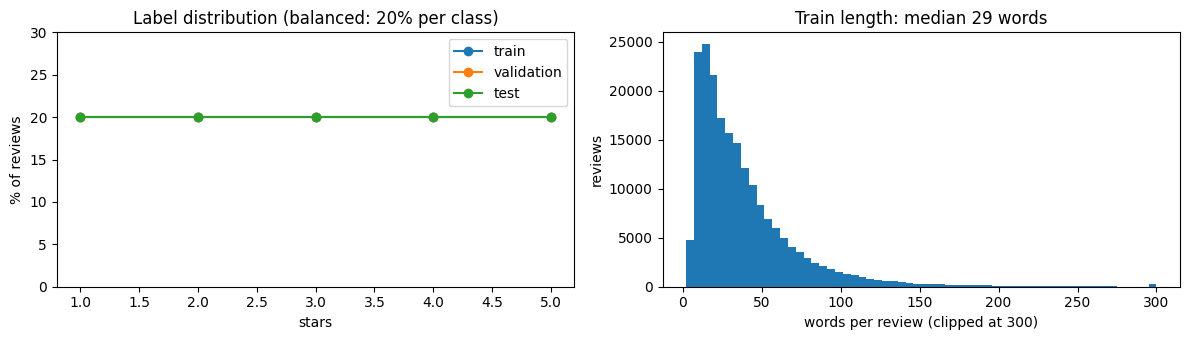

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for split in ["train", "validation", "test"]:
    counts = np.bincount(ds[split]["label"], minlength=5)
    axes[0].plot(range(1, 6), counts / counts.sum() * 100, marker="o", label=split)
axes[0].set(xlabel="stars", ylabel="% of reviews", title="Label distribution (balanced: 20% per class)", ylim=(0, 30))
axes[0].legend()
n_words = np.array([len(t.split()) for t in ds["train"]["text"]])
axes[1].hist(np.clip(n_words, 0, 300), bins=60)
axes[1].set(xlabel="words per review (clipped at 300)", ylabel="reviews", title=f"Train length: median {np.median(n_words):.0f} words")
plt.tight_layout(); plt.show()

## 2. Classic pipeline (BiGRU baseline)

Steps: `html.unescape` → strip HTML tags and URLs → lowercase → spaCy's rule-based English
tokenizer (`spacy.blank("en")`, no model download) → vocabulary built on the **training split
only** with `min_freq = 3` (+ `<pad>` = 0, `<unk>` = 1) → ids truncated to **200 tokens**
(padding is added per batch) → fastText `wiki-news-300d-1M` vectors (cased vectors are folded
to lowercase; words without a vector get small random vectors).

In [5]:
from src.data import clean_text, WordTokenizer
demo = "Great product!<br />See https://example.com/item?id=3 &amp; reviews. I DON'T regret it :)"
print("raw:      ", demo)
print("cleaned:  ", clean_text(demo))
print("tokens:   ", WordTokenizer("spacy").tokenize_many([clean_text(demo)])[0])

raw:       Great product!<br />See https://example.com/item?id=3 &amp; reviews. I DON'T regret it :)
cleaned:   great product! see & reviews. i don't regret it :)


tokens:    ['great', 'product', '!', 'see', '&', 'reviews', '.', 'i', 'do', "n't", 'regret', 'it', ':)']


In [6]:
from src.data import prepare_classic
# First run: tokenizes 210k reviews (~1-3 min) and downloads fastText (~0.7 GB zip, once).
classic_stats = prepare_classic("data", embeddings="fasttext", min_freq=3, max_len=200)
print(json.dumps(classic_stats, indent=1))

[09:27:40] [classic] cleaning + tokenizing train (200,000 reviews)


[09:28:07] [classic] cleaning + tokenizing validation (5,000 reviews)


[09:28:08] [classic] cleaning + tokenizing test (5,000 reviews)


[09:28:18] [emb] downloading https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip


    0.0% of 682 MB


   10.0% of 682 MB


... (8 outputs left out)

  100.0% of 682 MB


[09:28:42] [classic] building embedding matrix from data/embeddings/wiki-news-300d-1M.vec


[09:28:46] [classic] vocab=26,126  embedding coverage=96.2% of types


{
 "params": {
  "embeddings": "fasttext",
  "min_freq": 3,
  "max_len": 200,
  "tokenizer": "spacy"
 },
 "vocab_size": 26126,
 "train_types_before_min_freq": 50197,
 "train": {
  "n": 200000,
  "mean_tokens": 44.621055,
  "p95_tokens": 117.0,
  "truncated_frac": 0.00932,
  "unk_rate": 0.0034510713534471487
 },
 "validation": {
  "n": 5000,
  "mean_tokens": 45.0762,
  "p95_tokens": 117.0,
  "truncated_frac": 0.0094,
  "unk_rate": 0.004823885239453685
 },
 "test": {
  "n": 5000,
  "mean_tokens": 44.4236,
  "p95_tokens": 115.05000000000018,
  "truncated_frac": 0.0074,
  "unk_rate": 0.0051795077191960385
 },
 "embeddings": {
  "embedding_file": "data/embeddings/wiki-news-300d-1M.vec",
  "dim": 300,
  "vocab_words_with_vector": 25128,
  "type_coverage": 0.9618741387230133,
  "token_coverage_in_vocab": 0.9878253372055734,
  "token_coverage_all_train_tokens": 0.98441352406392
 }
}


text   : Fucking waste of money. This product is a piece of shit. Do not buy. Doesn't work, and then I try to call for customer support, it won't take my number. Fucking rip off!


tokens : ['fucking', 'waste', 'of', 'money', '.', 'this', 'product', 'is', 'a', 'piece', 'of', 'shit', '.', 'do', 'not', 'buy', '.', 'does', "n't", 'work', ',', 'and', 'then', 'i', 'try', 'to', 'call', 'for', 'customer', 'support', ',', 'it', 'wo', "n't", 'take', 'my', 'number', '.', 'fucking', 'rip']


ids    : [7892, 243, 14, 114, 2, 13, 37, 10, 9, 321, 14, 3143, 2, 35, 12, 87, 2, 43, 26, 60, 8, 6, 142, 4, 274, 7, 1084, 11, 421, 459, 8, 5, 238, 26, 259, 17, 980, 2, 7892, 1189]   (0 = <pad>, 1 = <unk>)
embedding matrix: (26126, 300) | vocabulary size: 26126


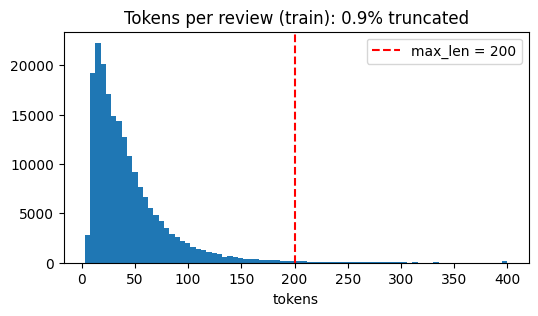

In [7]:
vocab = json.load(open("data/classic/vocab.json"))
tr = np.load("data/classic/train.npz")
i = 3
L = int(tr["lengths"][i])
print("text   :", ds["train"][i]["text"][:300])
print("tokens :", [vocab[j] for j in tr["ids"][i, :L]][:40])
print("ids    :", tr["ids"][i, :min(L, 40)].tolist(), "  (0 = <pad>, 1 = <unk>)")
emb = np.load("data/classic/embedding_matrix.npy")
print("embedding matrix:", emb.shape, "| vocabulary size:", len(vocab))

raw = tr["raw_lengths"]
plt.figure(figsize=(6, 3)); plt.hist(np.clip(raw, 0, 400), bins=80); plt.axvline(200, color="r", ls="--", label="max_len = 200")
plt.title(f"Tokens per review (train): {np.mean(raw > 200):.1%} truncated"); plt.xlabel("tokens"); plt.legend(); plt.show()

## 3. RoBERTa pipeline

`RobertaTokenizerFast` uses byte-level BPE (a leading space becomes `Ġ`), so there are no
unknown tokens. It adds `<s>` (id 0) and `</s>` (id 2); `<pad>` is id 1. Reviews are
truncated to **256** sub-word tokens (keeping `</s>`). No padding is stored: a
`DataCollatorWithPadding` pads each batch only to its own longest review (rounded up to a
multiple of 8 for tensor cores) and builds the `attention_mask`.

In [8]:
from src.data import load_roberta_tokenizer, prepare_roberta, roberta_cache_dir
tok = load_roberta_tokenizer("roberta-base")
enc = tok("Not bad at all. Doesn't fit my phone though!!")
print(tok.convert_ids_to_tokens(enc["input_ids"]))
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
print("special tokens:", {t: tok.convert_tokens_to_ids(t) for t in [tok.bos_token, tok.eos_token, tok.pad_token, tok.unk_token]})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

['<s>', 'Not', 'Ġbad', 'Ġat', 'Ġall', '.', 'ĠDoesn', "'t", 'Ġfit', 'Ġmy', 'Ġphone', 'Ġthough', '!!', '</s>']
input_ids     : [0, 7199, 1099, 23, 70, 4, 31455, 75, 2564, 127, 1028, 600, 12846, 2]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
special tokens: {'<s>': 0, '</s>': 2, '<pad>': 1, '<unk>': 3}


RoBERTa tokenization:   0%|          | 0/200000 [00:00<?, ? examples/s]

RoBERTa tokenization:   0%|          | 0/5000 [00:00<?, ? examples/s]

RoBERTa tokenization:   0%|          | 0/5000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/200000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5000 [00:00<?, ? examples/s]

[09:29:35] [roberta] tokenized -> data/roberta_roberta-base_len256  (train truncated: 0.4%)


DatasetDict({
    train: Dataset({
        features: ['id', 'label', 'input_ids', 'attention_mask', 'length', 'full_length'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'label', 'input_ids', 'attention_mask', 'length', 'full_length'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'label', 'input_ids', 'attention_mask', 'length', 'full_length'],
        num_rows: 5000
    })
})
{
 "model_name": "roberta-base",
 "max_len": 256,
 "train": {
  "mean_tokens": 48.85957,
  "median_tokens": 38.0,
  "p95_tokens": 124.0,
  "truncated_frac": 0.00443
 },
 "validation": {
  "mean_tokens": 49.413,
  "median_tokens": 37.0,
  "p95_tokens": 125.0,
  "truncated_frac": 0.0044
 },
 "test": {
  "mean_tokens": 48.589,
  "median_tokens": 38.0,
  "p95_tokens": 122.0,
  "truncated_frac": 0.0036
 }
}


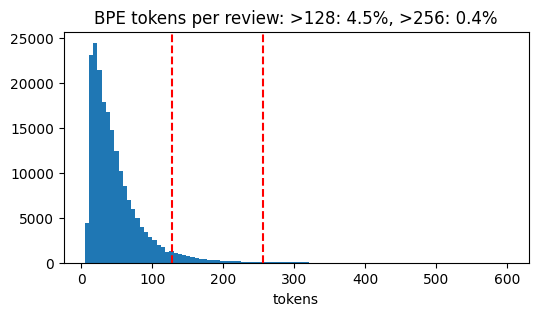

In [9]:
tokd = prepare_roberta("data", "roberta-base", max_len=256)
print(tokd)
print(json.dumps(json.load(open(roberta_cache_dir("data", "roberta-base", 256) / "tok_stats.json")), indent=1))
full = np.asarray(tokd["train"]["full_length"])
plt.figure(figsize=(6, 3)); plt.hist(np.clip(full, 0, 600), bins=100)
for x in (128, 256): plt.axvline(x, color="r", ls="--")
plt.title(f"BPE tokens per review: >128: {np.mean(full > 128):.1%}, >256: {np.mean(full > 256):.1%}"); plt.xlabel("tokens"); plt.show()

### Dynamic padding + length bucketing (efficiency)

Padding every review to 256 tokens wastes compute on `<pad>`. Below: number of token
positions processed per training epoch with (a) fixed padding to 256, (b) dynamic padding
with random batches, (c) dynamic padding with the length-bucketed sampler used in training.

In [10]:
from src.data import RobertaSplit
from src.utils import LengthBucketBatchSampler
train_split = RobertaSplit(tokd["train"], tok)
batch = train_split.collate([0, 1, 2, 3])
print({k: tuple(v.shape) for k, v in batch.items()})
print(batch["attention_mask"])

lens, B = train_split.batch_lengths(), 32
r8 = lambda x: (x + 7) // 8 * 8
fixed = len(lens) * 256
perm = np.random.default_rng(0).permutation(len(lens))
random_dyn = sum(r8(lens[perm[s:s + B]].max()) * len(perm[s:s + B]) for s in range(0, len(lens), B))
bucketed = sum(r8(lens[b].max()) * len(b) for b in LengthBucketBatchSampler(lens, B, shuffle=True, seed=0))
real = lens.sum()
for name, v in [("fixed padding to 256", fixed), ("dynamic padding", random_dyn), ("dynamic + length bucketing", bucketed)]:
    print(f"{name:28s}: {v / 1e6:7.1f} M positions/epoch  ({real / v:.0%} real tokens)")

{'input_ids': (4, 160), 'attention_mask': (4, 160), 'labels': (4,), 'idx': (4,)}
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

**Next:** `02_baseline_bigru_attention.ipynb` and `03_roberta_finetune_ablation.ipynb`
(both reuse the caches built here).